# Завдання 1

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

VARIANT = 'occupancy'   
#шлях до даних
DATA = Path('data')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

if VARIANT == 'bean':
    df = pd.read_csv(DATA / 'drybean.csv')
    target = 'Class'
    features = [c for c in df.columns if c not in ('Class', 'split')]
else:
    df = pd.read_csv(DATA / 'occupancy.csv')
    target = 'Occupancy'
    features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

#дані вже розмічені
train, val, test = (df[df['split'] == s] for s in ('train', 'val', 'test'))
X_tr, y_tr = train[features], train[target]
X_va, y_va = val[features], val[target]
X_te, y_te = test[features], test[target]
print('train / validation / test:', len(train), len(val), len(test))

train / validation / test: 8143 2665 9752


In [65]:
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,split
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1,train
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1,train
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1,train
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1,train
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1,train


In [66]:
df.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031
std,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000
50%,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000
75%,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000
max,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000


In [67]:
print ("Features:", len(features))
print ("Classes:", len(y_tr.unique()))
print(y_tr.value_counts())

Features: 5
Classes: 2
Occupancy
0    6414
1    1729
Name: count, dtype: int64


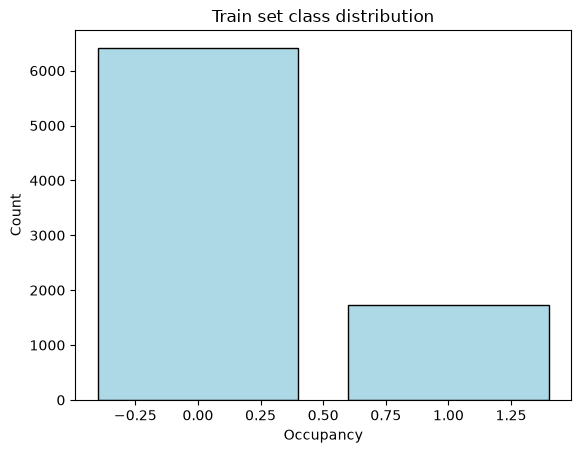

In [68]:
plt.bar(y_tr.value_counts().index, y_tr.value_counts().values, color='lightblue', edgecolor='black')
plt.title('Train set class distribution')
plt.xlabel('Occupancy')
plt.ylabel('Count')
plt.show()

In [69]:
class_0 = y_tr.mode()[0]
print((y_va == class_0).mean(), " - точність, якщо завжди передбачати клас", class_0)

0.6352720450281426  - точність, якщо завжди передбачати клас 0


# Завдання 2

In [70]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_tr, y_tr)

print("Accuracy:")
print("train:", tree.score(X_tr, y_tr))
print("validation:", tree.score(X_va, y_va))

Accuracy:
train: 0.9893159769126857
validation: 0.9782363977485928


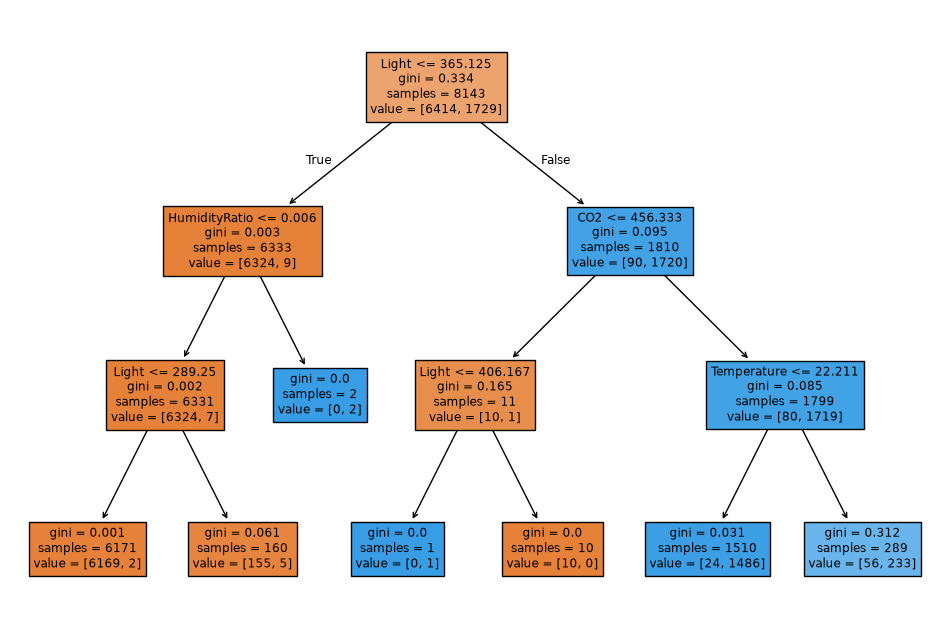

In [71]:
plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=features, filled=True)
plt.show()

Якщо Light не перевищує 365.12, дерево переважно відносить запис до класу 0 - у кімнаті нікого немає.

In [72]:
print(export_text(tree, feature_names=features))

|--- Light <= 365.12
|   |--- HumidityRatio <= 0.01
|   |   |--- Light <= 289.25
|   |   |   |--- class: 0
|   |   |--- Light >  289.25
|   |   |   |--- class: 0
|   |--- HumidityRatio >  0.01
|   |   |--- class: 1
|--- Light >  365.12
|   |--- CO2 <= 456.33
|   |   |--- Light <= 406.17
|   |   |   |--- class: 1
|   |   |--- Light >  406.17
|   |   |   |--- class: 0
|   |--- CO2 >  456.33
|   |   |--- Temperature <= 22.21
|   |   |   |--- class: 1
|   |   |--- Temperature >  22.21
|   |   |   |--- class: 1



# Завдання 3

In [73]:
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_tr, y_tr)

print("Accuracy:")
print("train:", forest.score(X_tr, y_tr))
print("validation:", forest.score(X_va, y_va))

Accuracy:
train: 1.0
validation: 0.949343339587242


In [74]:
pred = [None, None]
pred[0] = tree.predict(X_va)
pred[1] = forest.predict(X_va)

print("- Tree")
print(f"Accuracy: {tree.score(X_va, y_va):.3f}")
print(f"Precision: {precision_score(y_va, pred[0], average='macro'):.3f}")
print(f"Recall: {recall_score(y_va, pred[0], average='macro'):.3f}")
print()
print("- Random Forest")
print(f"Accuracy: {forest.score(X_va, y_va):.3f}")
print(f"Precision: {precision_score(y_va, pred[1], average='macro'):.3f}")
print(f"Recall: {recall_score(y_va, pred[1], average='macro'):.3f}")

- Tree
Accuracy: 0.978
Precision: 0.972
Recall: 0.982

- Random Forest
Accuracy: 0.949
Precision: 0.949
Recall: 0.942


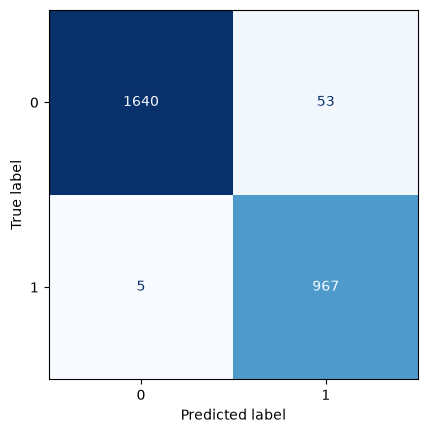

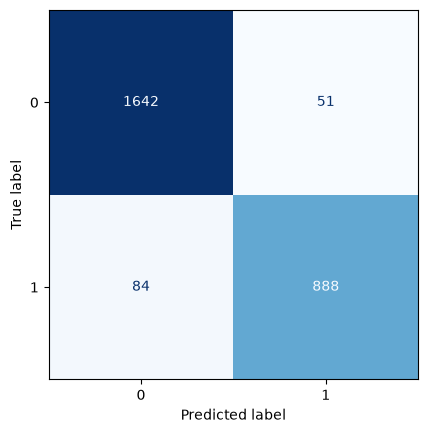

In [75]:
disp = ConfusionMatrixDisplay.from_estimator(tree, X_va, y_va, cmap='Blues', colorbar=False)
disp2 = ConfusionMatrixDisplay.from_estimator(forest, X_va, y_va, cmap='Blues', colorbar=False)

Дерево точніше за випадковий ліс. У випадкового лісу більше пропущених людей, ніж хибних тривог. 84/51

# Завдання 4

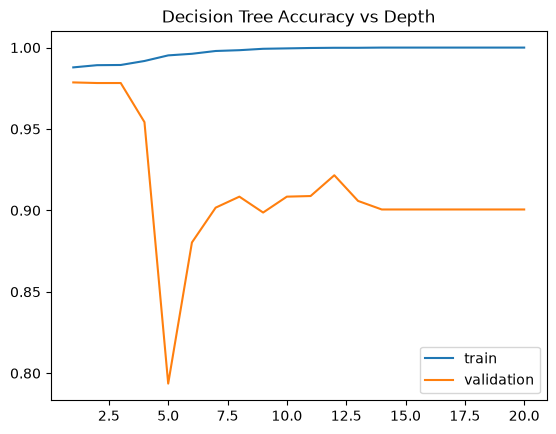

In [76]:
train_scores = []
val_scores = []

for depth in range(1, 21):
    model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    model.fit(X_tr, y_tr)

    train_scores.append(model.score(X_tr, y_tr))
    val_scores.append(model.score(X_va, y_va))

plt.plot(range(1, 21), train_scores, label='train',)
plt.plot(range(1, 21), val_scores, label='validation')
plt.title('Decision Tree Accuracy vs Depth')
plt.legend()
plt.show()

In [77]:
best_depth = val_scores.index(max(val_scores)) + 1
print("Best depth:", best_depth)
print("Validation accuracy:", max(val_scores))

Best depth: 1
Validation accuracy: 0.9786116322701689


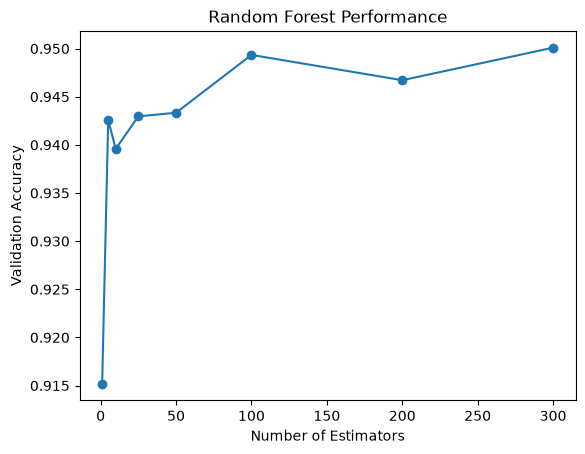

In [78]:
scores = []
n_estimators = [1, 5, 10, 25, 50, 100, 200, 300]

for n in n_estimators:
    model = RandomForestClassifier(n_estimators=n, random_state=0)
    model.fit(X_tr, y_tr)
    scores.append(model.score(X_va, y_va))

plt.plot(n_estimators, scores, marker='o')
plt.xlabel('Number of Estimators')
plt.ylabel('Validation Accuracy')
plt.title('Random Forest Performance')
plt.show()

In [79]:
best_n_estimators = n_estimators[scores.index(max(scores))]
print("Best number of estimators:", best_n_estimators)

Best number of estimators: 300


In [80]:
best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0)
best_tree.fit(X_tr, y_tr)

best_forest = RandomForestClassifier(n_estimators=best_n_estimators, random_state=0)
best_forest.fit(X_tr, y_tr)

print("Decision Tree test:", best_tree.score(X_te, y_te))
print("Random Forest test:", best_forest.score(X_te, y_te))

Decision Tree test: 0.993129614438064
Random Forest test: 0.9730311730926989


# Завдання 5

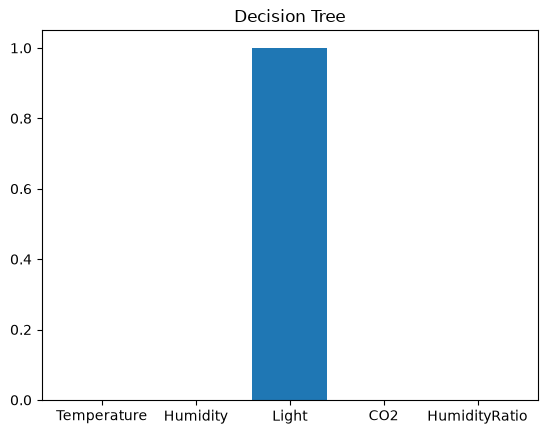

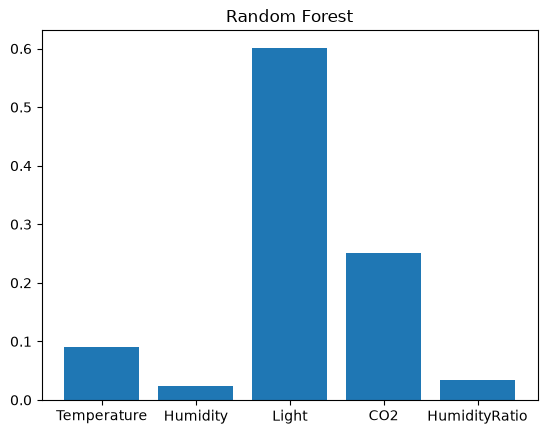

In [81]:
plt.bar(features, best_tree.feature_importances_)
plt.title("Decision Tree")
plt.show()

plt.bar(features, best_forest.feature_importances_)
plt.title("Random Forest")
plt.show()

In [82]:
best_features = [features[i] for i in best_forest.feature_importances_.argsort()[-3:][::-1]]
print(best_features)

['Light', 'CO2', 'Temperature']


In [83]:
new_features = [feat for feat in features if feat != "Light"]

forest_without_light = RandomForestClassifier(n_estimators=100, random_state=0)
forest_without_light.fit(X_tr[new_features], y_tr)

print("- Validation")
print("Original forest:", forest.score(X_va, y_va))
print("Without Light:", forest_without_light.score(X_va[new_features], y_va))

print("- Test")
print("Original forest:", forest.score(X_te, y_te))
print("Without Light:", forest_without_light.score(X_te[new_features], y_te))

- Validation
Original forest: 0.949343339587242
Without Light: 0.6848030018761726
- Test
Original forest: 0.9729286300246104
Without Light: 0.3339827727645611


Original forest


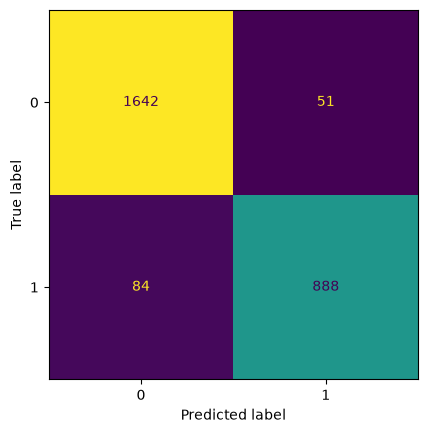

In [84]:
ConfusionMatrixDisplay.from_estimator(forest, X_va, y_va, colorbar=False)

print("Original forest")

Without Light


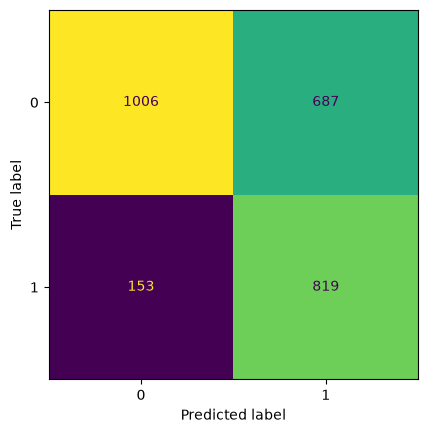

In [85]:
ConfusionMatrixDisplay.from_estimator(forest_without_light, X_va[new_features], y_va, colorbar=False)

print("Without Light")

# Завдання 6

In [86]:
new_data = pd.DataFrame([
    [23, 30, 100, 1200, 0.005],
    [22, 28, 300, 1000, 0.0045],
    [21, 27, 370, 450, 0.004]
], columns=features)
# згенеровані так, щоб прогнози не збігалися

new_data.head()

,Temperature,Humidity,Light,CO2,HumidityRatio
0,23,30,100,1200,0.0050
1,22,28,300,1000,0.0045
2,21,27,370,450,0.0040


In [87]:
print("Decision Tree:", best_tree.predict(new_data))
print("Random Forest:", best_forest.predict(new_data))

Decision Tree: [0 0 1]
Random Forest: [0 1 0]


In [88]:
print(best_forest.predict_proba(new_data))

[[0.88333333 0.11666667]
 [0.21666667 0.78333333]
 [0.57666667 0.42333333]]


# Завдання 7

<img src="calc.png" height="900">

In [89]:
t = tree.tree_

left = t.children_left[0]
right = t.children_right[0]

p = t.value[0][0]
gini = 1 - sum(p ** 2)
print("Корінь:", gini)

p = t.value[left][0]
gini = 1 - sum(p ** 2)
print("Лівий:", gini)

p = t.value[right][0]
gini = 1 - sum(p ** 2)
print("Правий:", gini)

Корінь: 0.3344914914236645
Лівий: 0.002838215649186848
Правий: 0.09450260981044534


In [90]:
n = t.n_node_samples

g_after = (n[left] * t.impurity[left] + n[right] * t.impurity[right]) / n[0]

print("Gini після:", g_after)
print("Зменшення:", t.impurity[0] - g_after)

Gini після: 0.023213084055410338
Зменшення: 0.3112784073682542


In [91]:
pred = forest.predict(X_va)
print("Precision:", round(precision_score(y_va, pred), 5))
print("Recall:", round(recall_score(y_va, pred), 5))

Precision: 0.94569
Recall: 0.91358


In [92]:
n = len(y_tr)
p = (1 - 1/n) ** n

print("P =", p)
print("Не потрапить:", round(p, 5))
print("Потрапить:", round(1-p, 5))

P = 0.36785685132330115
Не потрапить: 0.36786
Потрапить: 0.63214


## Висновки

1. Завдання 1. У датасеті Occupancy Detection є 5 ознак і 2 класи. Класи незбалансовані, записів без людей більше.

2. Завдання 2. Перша умова перевіряє освітленість `Light`.

3. Завдання 3. На валідаційній вибірці дерево показало точність 97.8%, а випадковий ліс - 94.9%.

4. Завдання 4. Найкраща глибина дерева - 1. Зі збільшенням глибини починається перенавчання. Для випадкового лісу достатньо 100 дерев, оскільки подальше збільшення їх кількості майже не покращує результат, окрім результату з 300, яке виявилося найкращим.

5. Завдання 5. Три найважливіші ознаки - `Light`, `CO2` і `Temperature`. Без `Light` точність випадкового лісу значно зменшилася, оскільки освітленість сильно пов'язана з присутністю людей.

6. Завдання 6. Дерево і випадковий ліс дали різні прогнози, тому що найкраще дерево враховує лише `Light`, а випадковий ліс використовує декілька ознак включно з освітленням.

7. Завдання 7. Ручні обчислення та перевірка кодом дали +- однакові (дуже близькі) результати. Після першого поділу індекс Джині зменшився. Precision для класу 1 становить 94.6%, Recall - 91.3%. Приблизно 36.8% навчальних записів не потрапляють до бутстреп-вибірки окремого дерева.